# EfficientNet-B0 Results & Evaluation

Covers: training curves · per-subclass recall · PR/ROC curves · confusion matrices · per-original-label metrics · Phase 7 diagnosis.

In [29]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from sklearn.metrics import (
    roc_curve, auc,
    precision_recall_curve, average_precision_score,
    confusion_matrix, classification_report,
    matthews_corrcoef,
)

sys.path.insert(0, str(Path("..") / "src"))
from kvasir_triage.data.labels import SUSPICIOUS_CLASSES, NORMAL_CLASSES, BINARY_LABEL

plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

In [30]:
RUNS_ROOT = Path("../outputs/runs")

CONFIG_NAMES = ["efficientnet_b0"]
DISPLAY_NAMES = {
    "efficientnet_b0": "EfficientNet-B0",
}
COLORS = {
    "efficientnet_b0": "#4CAF50",
}
FOLD_LS = {0: "-", 1: "--"}
THRESHOLD = 0.5

SUSPICIOUS = sorted(SUSPICIOUS_CLASSES)
NORMAL     = sorted(NORMAL_CLASSES)
ALL_SUBCLASSES = SUSPICIOUS + NORMAL

In [31]:
def find_runs(config_name: str) -> dict:
    """Return {fold: run_dir} for the most recent run of each fold."""
    result = {}
    for fold in [0, 1]:
        candidates = sorted(RUNS_ROOT.glob(f"{config_name}_fold{fold}_*"))
        if candidates:
            result[fold] = candidates[-1]
    return result


def load_metrics(run_dir: Path) -> pd.DataFrame:
    path = run_dir / "metrics.jsonl"
    if not path.exists():
        return pd.DataFrame()
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    df = pd.DataFrame(rows)
    return df.replace({None: float("nan")})


def load_preds(run_dir: Path):
    """Return (logits, labels, subclasses) arrays or None."""
    path = run_dir / "val_preds_best.npz"
    if not path.exists():
        return None
    d = np.load(path, allow_pickle=True)
    return d["logits"], d["labels"], d["subclasses"].astype(str)


# ── discover ──────────────────────────────────────────────────────────────────
all_runs = {cfg: find_runs(cfg) for cfg in CONFIG_NAMES}

print("Discovered runs:")
for cfg, folds in all_runs.items():
    if folds:
        for fold, path in folds.items():
            preds_ok = (path / "val_preds_best.npz").exists()
            print(f"  {cfg} fold {fold}  →  {path.name}  [preds: {'yes' if preds_ok else 'no'}]")
    else:
        print(f"  {cfg}: no runs found")

Discovered runs:
  efficientnet_b0 fold 0  →  efficientnet_b0_fold0_20260525_224526  [preds: yes]
  efficientnet_b0 fold 1  →  efficientnet_b0_fold1_20260525_224526  [preds: yes]


## 1 · Training curves

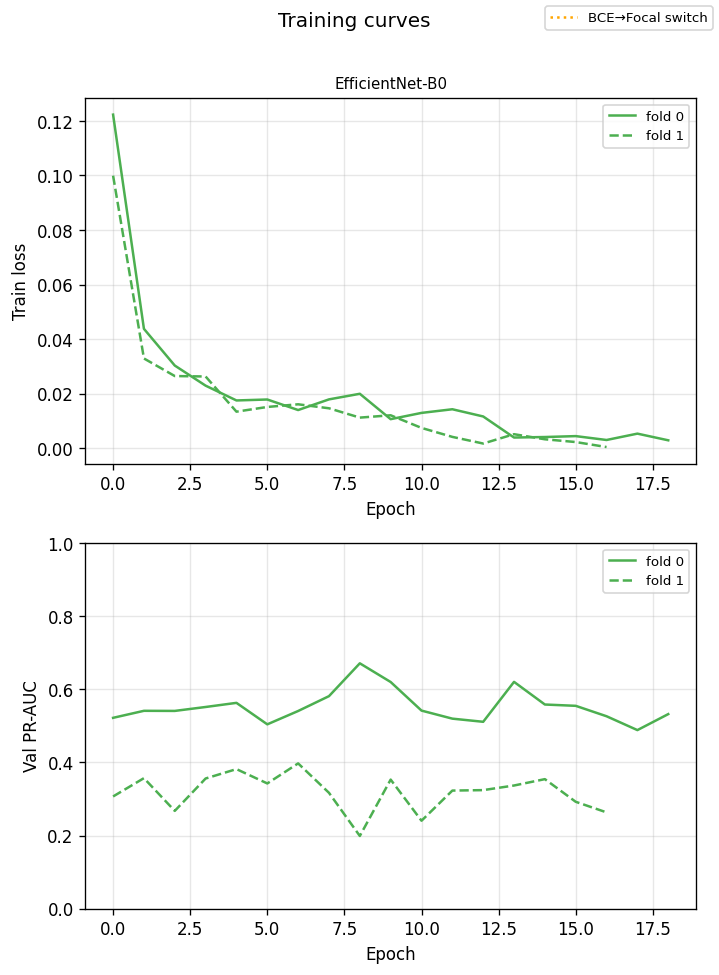

In [32]:
cfg = CONFIG_NAMES[0]
color = COLORS[cfg]

fig, (ax_loss, ax_prauc) = plt.subplots(2, 1, figsize=(6, 8))

has_any = False
for fold, run_dir in all_runs[cfg].items():
    df = load_metrics(run_dir)
    if df.empty:
        continue
    has_any = True
    ls = FOLD_LS[fold]
    label = f"fold {fold}"

    if "train_loss" in df.columns:
        ax_loss.plot(df["epoch"], df["train_loss"], color=color, ls=ls, label=label)
        if "loss_switched" in df.columns:
            switch_epochs = df[df["loss_switched"] == True]["epoch"]
            for ep in switch_epochs:
                ax_loss.axvline(ep, color="orange", lw=1, ls=":", alpha=0.8)

    if "val_pr_auc" in df.columns:
        ax_prauc.plot(df["epoch"], df["val_pr_auc"], color=color, ls=ls, label=label)

ax_loss.set_title(DISPLAY_NAMES[cfg], fontsize=9)
ax_loss.set_xlabel("Epoch")
ax_loss.set_ylabel("Train loss")
ax_prauc.set_xlabel("Epoch")
ax_prauc.set_ylabel("Val PR-AUC")

if has_any:
    ax_loss.legend(fontsize=8)
    ax_prauc.legend(fontsize=8)

ax_loss.grid(True, alpha=0.3)
ax_prauc.grid(True, alpha=0.3)
ax_prauc.set_ylim(0, 1)

switch_patch = Line2D([0], [0], color="orange", ls=":", label="BCE→Focal switch")
fig.legend(handles=[switch_patch], loc="upper right", fontsize=8)

fig.suptitle("Training curves", fontsize=12, y=1.01)
fig.tight_layout()
plt.show()

## 2 · Final metrics summary

In [33]:
rows = []
for cfg in CONFIG_NAMES:
    for fold, run_dir in all_runs[cfg].items():
        df = load_metrics(run_dir)
        if df.empty:
            continue
        best = df.loc[df["val_pr_auc"].idxmax()]
        rows.append({
            "model":      DISPLAY_NAMES[cfg],
            "fold":       fold,
            "epoch":      int(best["epoch"]),
            "pr_auc":     round(float(best["val_pr_auc"]), 4),
            "mcc":        round(float(best.get("val_mcc", float("nan"))), 4),
            "npv":        round(float(best.get("val_npv",  float("nan"))), 4),
            "loss_fn":    best.get("loss_fn", "bce"),
        })

summary_df = pd.DataFrame(rows)

if not summary_df.empty:
    cv = (
        summary_df.groupby("model")[["pr_auc", "mcc", "npv"]]
        .agg(["mean", "std"])
        .round(4)
    )
    print("Per-fold results:")
    display(summary_df)
    print("\nCV mean ± std:")
    display(cv)
else:
    print("No completed runs found.")

Per-fold results:


,model,fold,epoch,pr_auc,mcc,npv,loss_fn
0,EfficientNet-B0,0,8,0.6710,0.6194,0.9612,bce
1,EfficientNet-B0,1,6,0.3973,0.3599,0.9491,bce



CV mean ± std:


pr_auc             mcc             npv        
                   mean     std    mean     std    mean     std
model                                                          
EfficientNet-B0  0.5342  0.1935  0.4896  0.1835  0.9552  0.0086

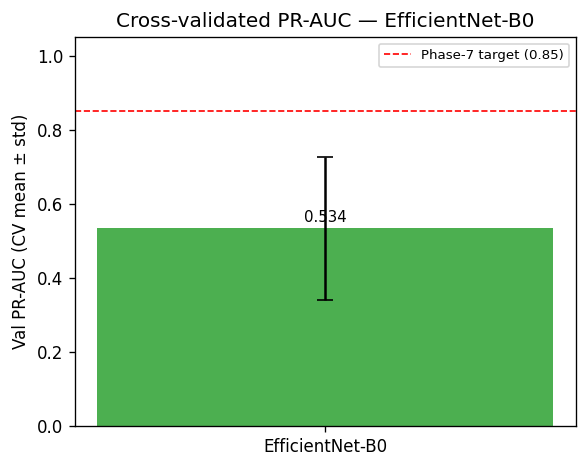

In [34]:
if not summary_df.empty:
    cv_mean = summary_df.groupby("model")["pr_auc"].mean().sort_values(ascending=False)
    cv_std  = summary_df.groupby("model")["pr_auc"].std().reindex(cv_mean.index)

    fig, ax = plt.subplots(figsize=(5, 4))
    colors = [COLORS[k] for k in CONFIG_NAMES if DISPLAY_NAMES[k] in cv_mean.index]
    bars = ax.bar(cv_mean.index, cv_mean.values, yerr=cv_std.values,
                  color=colors, capsize=5, width=0.4, error_kw={"elinewidth": 1.5})
    ax.set_ylabel("Val PR-AUC (CV mean ± std)")
    ax.set_ylim(0, 1.05)
    ax.axhline(0.85, color="red", ls="--", lw=1, label="Phase-7 target (0.85)")
    ax.legend(fontsize=8)
    for bar, val in zip(bars, cv_mean.values):
        ax.text(bar.get_x() + bar.get_width() / 2, val + 0.01, f"{val:.3f}",
                ha="center", va="bottom", fontsize=9)
    ax.set_title("Cross-validated PR-AUC — EfficientNet-B0")
    fig.tight_layout()
    plt.show()

## 3 · Per-subclass recall over training

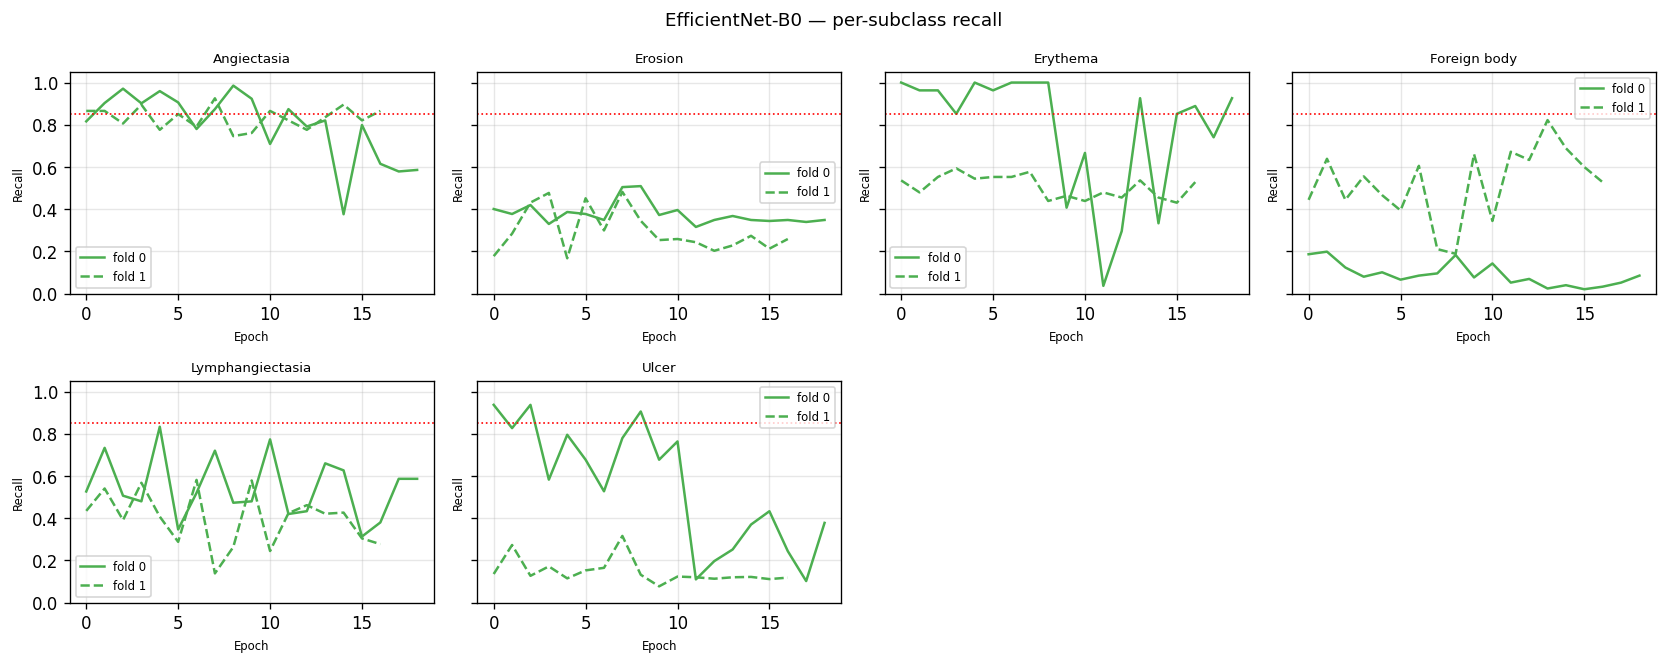

In [35]:
for cfg in CONFIG_NAMES:
    folds_data = {}
    recall_cols = None
    for fold, run_dir in all_runs[cfg].items():
        df = load_metrics(run_dir)
        if df.empty:
            continue
        cols = [c for c in df.columns if c.startswith("recall_")]
        if not cols:
            continue
        recall_cols = cols
        folds_data[fold] = df

    if not folds_data or not recall_cols:
        continue

    subclasses = [c.replace("recall_", "") for c in recall_cols]
    n = len(subclasses)
    ncols = 4
    nrows = (n + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.5, nrows * 2.8), sharey=True)
    axes_flat = axes.flatten() if n > 1 else [axes]

    for i, (sub, col) in enumerate(zip(subclasses, recall_cols)):
        ax = axes_flat[i]
        for fold, df in folds_data.items():
            if col in df.columns:
                ax.plot(df["epoch"], df[col], ls=FOLD_LS[fold],
                        color=COLORS[cfg], label=f"fold {fold}")
        ax.axhline(0.85, color="red", ls=":", lw=1)
        ax.set_title(sub, fontsize=8)
        ax.set_ylim(0, 1.05)
        ax.set_xlabel("Epoch", fontsize=7)
        ax.set_ylabel("Recall", fontsize=7)
        ax.legend(fontsize=7)
        ax.grid(True, alpha=0.3)

    for j in range(i + 1, len(axes_flat)):
        axes_flat[j].set_visible(False)

    fig.suptitle(f"{DISPLAY_NAMES[cfg]} — per-subclass recall", fontsize=11)
    fig.tight_layout()
    plt.show()

## 4 · Final per-subclass recall heatmap

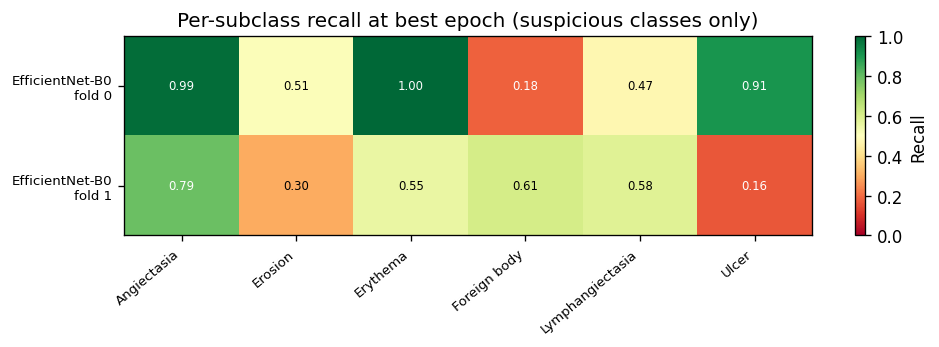

In [36]:
heatmap_rows = []
for cfg in CONFIG_NAMES:
    for fold, run_dir in all_runs[cfg].items():
        df = load_metrics(run_dir)
        if df.empty:
            continue
        best = df.loc[df["val_pr_auc"].idxmax()]
        row = {"model": DISPLAY_NAMES[cfg], "fold": fold}
        for col in [c for c in df.columns if c.startswith("recall_")]:
            row[col.replace("recall_", "")] = float(best[col])
        heatmap_rows.append(row)

if heatmap_rows:
    hm_df = pd.DataFrame(heatmap_rows).set_index(["model", "fold"])
    subclass_cols = [c for c in hm_df.columns]

    fig, ax = plt.subplots(figsize=(max(8, len(subclass_cols) * 1.4), max(3, len(hm_df) * 0.6)))
    im = ax.imshow(hm_df[subclass_cols].values.astype(float), aspect="auto",
                   vmin=0, vmax=1, cmap="RdYlGn")
    ax.set_xticks(range(len(subclass_cols)))
    ax.set_xticklabels(subclass_cols, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(len(hm_df)))
    ax.set_yticklabels([f"{m}\nfold {f}" for m, f in hm_df.index], fontsize=8)
    for i in range(len(hm_df)):
        for j in range(len(subclass_cols)):
            v = hm_df.iloc[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    fontsize=7, color="black" if 0.25 < v < 0.75 else "white")
    plt.colorbar(im, ax=ax, label="Recall")
    ax.set_title("Per-subclass recall at best epoch (suspicious classes only)")
    fig.tight_layout()
    plt.show()
else:
    print("No per-subclass recall data available yet.")

## 5 · PR curves & ROC curves

C:\Users\jordi\AppData\Local\Temp\ipykernel_20172\2700956296.py:10: RuntimeWarning: overflow encountered in exp
  probs = 1 / (1 + np.exp(-logits))
C:\Users\jordi\AppData\Local\Temp\ipykernel_20172\2700956296.py:10: RuntimeWarning: overflow encountered in exp
  probs = 1 / (1 + np.exp(-logits))


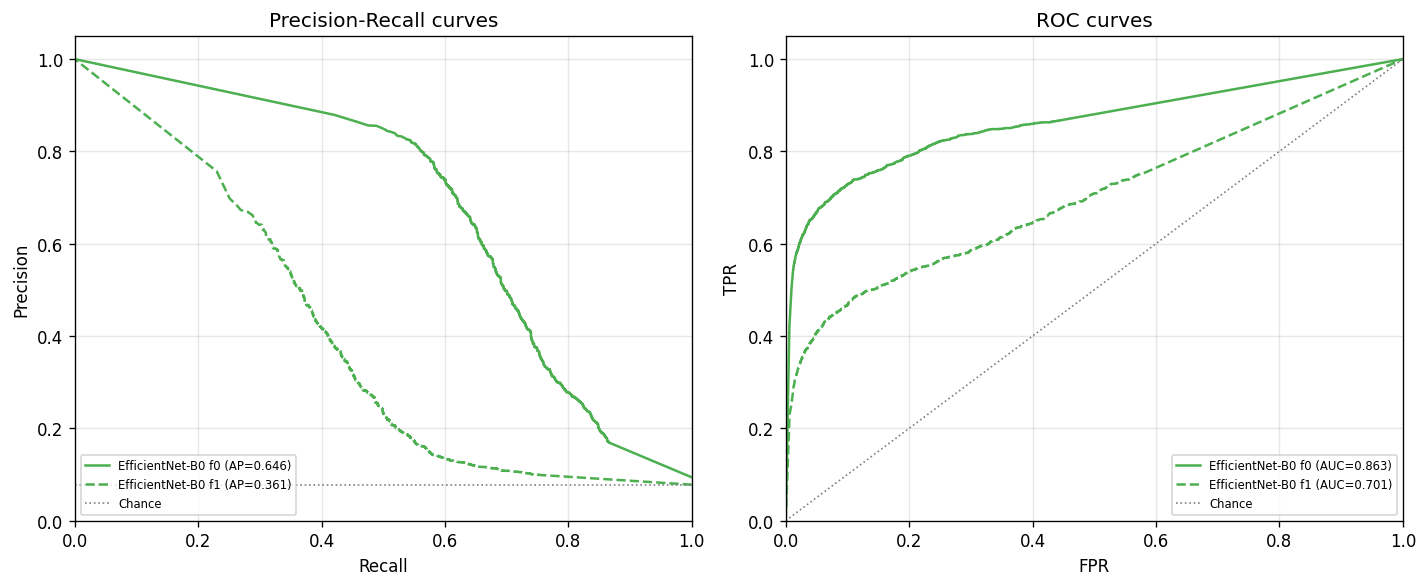

In [37]:
fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(12, 5))

has_any = False
for cfg in CONFIG_NAMES:
    for fold, run_dir in all_runs[cfg].items():
        preds = load_preds(run_dir)
        if preds is None:
            continue
        logits, labels, _ = preds
        probs = 1 / (1 + np.exp(-logits))
        has_any = True
        label_str = f"{DISPLAY_NAMES[cfg]} f{fold}"
        color = COLORS[cfg]

        prec, rec, _ = precision_recall_curve(labels, probs)
        ap = average_precision_score(labels, probs)
        ax_pr.plot(rec, prec, color=color, ls=FOLD_LS[fold],
                   label=f"{label_str} (AP={ap:.3f})")

        fpr, tpr, _ = roc_curve(labels, probs)
        roc_auc = auc(fpr, tpr)
        ax_roc.plot(fpr, tpr, color=color, ls=FOLD_LS[fold],
                    label=f"{label_str} (AUC={roc_auc:.3f})")

ax_pr.axhline(labels.mean() if has_any else 0.5, color="grey", ls=":", lw=1, label="Chance")
ax_roc.plot([0, 1], [0, 1], color="grey", ls=":", lw=1, label="Chance")

ax_pr.set_xlabel("Recall"); ax_pr.set_ylabel("Precision")
ax_pr.set_xlim(0, 1); ax_pr.set_ylim(0, 1.05)
ax_pr.set_title("Precision-Recall curves")
ax_pr.legend(fontsize=7, loc="lower left")
ax_pr.grid(True, alpha=0.3)

ax_roc.set_xlabel("FPR"); ax_roc.set_ylabel("TPR")
ax_roc.set_xlim(0, 1); ax_roc.set_ylim(0, 1.05)
ax_roc.set_title("ROC curves")
ax_roc.legend(fontsize=7, loc="lower right")
ax_roc.grid(True, alpha=0.3)

if not has_any:
    for ax in (ax_pr, ax_roc):
        ax.text(0.5, 0.5, "val_preds_best.npz\nnot found",
                ha="center", va="center", transform=ax.transAxes, fontsize=10, color="grey")

fig.tight_layout()
plt.show()

## 6 · Confusion matrix

C:\Users\jordi\AppData\Local\Temp\ipykernel_20172\197566931.py:16: RuntimeWarning: overflow encountered in exp
  probs  = 1 / (1 + np.exp(-logits))


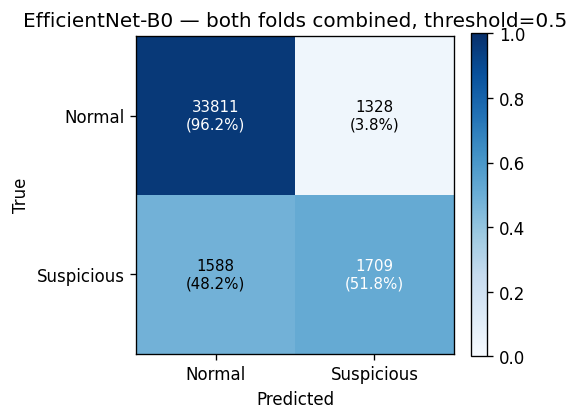

In [38]:
cfg = CONFIG_NAMES[0]
all_logits, all_labels = [], []
for fold, run_dir in all_runs[cfg].items():
    preds = load_preds(run_dir)
    if preds is None:
        continue
    logits, labels, _ = preds
    all_logits.append(logits)
    all_labels.append(labels)

if not all_logits:
    print("No val_preds_best.npz files found yet.")
else:
    logits = np.concatenate(all_logits)
    labels = np.concatenate(all_labels)
    probs  = 1 / (1 + np.exp(-logits))
    preds_bin = (probs >= THRESHOLD).astype(int)

    cm = confusion_matrix(labels, preds_bin)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig, ax = plt.subplots(figsize=(4.5, 4))
    im = ax.imshow(cm_pct, vmin=0, vmax=1, cmap="Blues")
    tick_labels = ["Normal", "Suspicious"]
    ax.set_xticks([0, 1]); ax.set_xticklabels(tick_labels)
    ax.set_yticks([0, 1]); ax.set_yticklabels(tick_labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")

    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i,j]}\n({cm_pct[i,j]:.1%})",
                    ha="center", va="center",
                    color="white" if cm_pct[i, j] > 0.5 else "black", fontsize=9)

    ax.set_title(f"{DISPLAY_NAMES[cfg]} — both folds combined, threshold={THRESHOLD}")
    plt.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    plt.show()

## 7 · Per-original-label metrics

Precision, recall, and F1 for each of the 11 subclasses (binary predictions at threshold 0.5).

In [39]:
def per_label_metrics(logits, labels, subclasses, threshold=0.5):
    """Compute precision, recall, F1, support for each subclass."""
    probs = 1 / (1 + np.exp(-logits))
    preds = (probs >= threshold).astype(int)
    rows = []
    for sub in np.unique(subclasses):
        mask = subclasses == sub
        y_true = labels[mask]
        y_pred = preds[mask]
        tp = int(((y_pred == 1) & (y_true == 1)).sum())
        fp = int(((y_pred == 1) & (y_true == 0)).sum())
        tn = int(((y_pred == 0) & (y_true == 0)).sum())
        fn = int(((y_pred == 0) & (y_true == 1)).sum())
        prec  = tp / (tp + fp) if (tp + fp) > 0 else float("nan")
        rec   = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
        spec  = tn / (tn + fp) if (tn + fp) > 0 else float("nan")
        f1    = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else float("nan")
        rows.append({
            "subclass": sub,
            "binary_label": int(BINARY_LABEL.get(sub, -1)),
            "n": int(mask.sum()),
            "precision": round(prec, 3),
            "recall": round(rec, 3),
            "specificity": round(spec, 3),
            "f1": round(f1, 3),
            "tp": tp, "fp": fp, "tn": tn, "fn": fn,
        })
    return pd.DataFrame(rows).sort_values(["binary_label", "subclass"])


label_tables = {}
for cfg in CONFIG_NAMES:
    all_logits, all_labels, all_subs = [], [], []
    for fold, run_dir in all_runs[cfg].items():
        preds = load_preds(run_dir)
        if preds is None:
            continue
        logits, labels, subclasses = preds
        all_logits.append(logits)
        all_labels.append(labels)
        all_subs.append(subclasses)
    if all_logits:
        t = per_label_metrics(
            np.concatenate(all_logits),
            np.concatenate(all_labels),
            np.concatenate(all_subs),
        )
        label_tables[cfg] = t
        print(f"── {DISPLAY_NAMES[cfg]} ──")
        display(t.set_index("subclass")[["binary_label", "n", "precision", "recall", "f1", "specificity"]])

if not label_tables:
    print("No val_preds_best.npz files found yet.")

C:\Users\jordi\AppData\Local\Temp\ipykernel_20172\3831719843.py:3: RuntimeWarning: overflow encountered in exp
  probs = 1 / (1 + np.exp(-logits))


── EfficientNet-B0 ──


,binary_label,n,precision,recall,f1,specificity
subclass,,,,,,
Ileocecal valve,0,3180,0.0,NaN,NaN,0.941
Normal clean mucosa,0,28323,0.0,NaN,NaN,0.972
Pylorus,0,1201,0.0,NaN,NaN,0.877
Reduced mucosal view,0,2435,0.0,NaN,NaN,0.921
Angiectasia,1,758,1.0,0.968,0.984,NaN
Erosion,1,409,1.0,0.411,0.582,NaN
Erythema,1,150,1.0,0.633,0.776,NaN
Foreign body,1,753,1.0,0.284,0.443,NaN
Lymphangiectasia,1,518,1.0,0.552,0.711,NaN


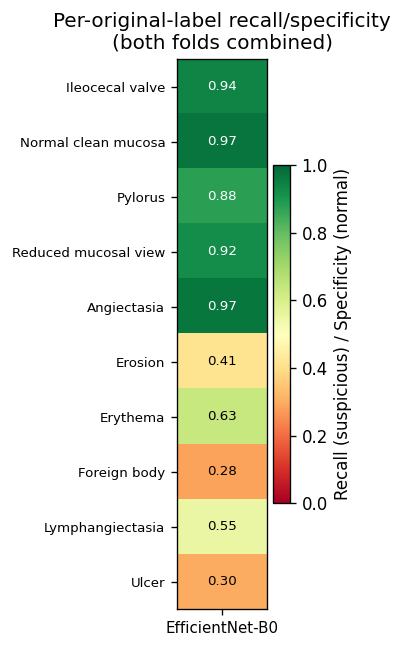

In [40]:
if label_tables:
    cfg = CONFIG_NAMES[0]
    t = label_tables[cfg]
    subclasses_all = t["subclass"].tolist()
    # Recall for suspicious (binary_label=1), specificity for normal (binary_label=0)
    display_vals = np.where(
        t["binary_label"].values == 1,
        t["recall"].values,
        t["specificity"].values,
    ).astype(float)

    fig, ax = plt.subplots(figsize=(3, max(4, len(subclasses_all) * 0.55)))
    im = ax.imshow(display_vals.reshape(-1, 1), aspect="auto", vmin=0, vmax=1, cmap="RdYlGn")
    ax.set_xticks([0])
    ax.set_xticklabels([DISPLAY_NAMES[cfg]], fontsize=9)
    ax.set_yticks(range(len(subclasses_all)))
    ax.set_yticklabels(subclasses_all, fontsize=8)

    for i, v in enumerate(display_vals):
        if not np.isnan(v):
            ax.text(0, i, f"{v:.2f}", ha="center", va="center",
                    fontsize=8, color="black" if 0.25 < v < 0.75 else "white")

    plt.colorbar(im, ax=ax, label="Recall (suspicious) / Specificity (normal)")
    ax.set_title("Per-original-label recall/specificity\n(both folds combined)")
    fig.tight_layout()
    plt.show()

## 8 · Optimal threshold analysis

C:\Users\jordi\AppData\Local\Temp\ipykernel_20172\1862560371.py:15: RuntimeWarning: overflow encountered in exp
  probs  = 1 / (1 + np.exp(-logits))


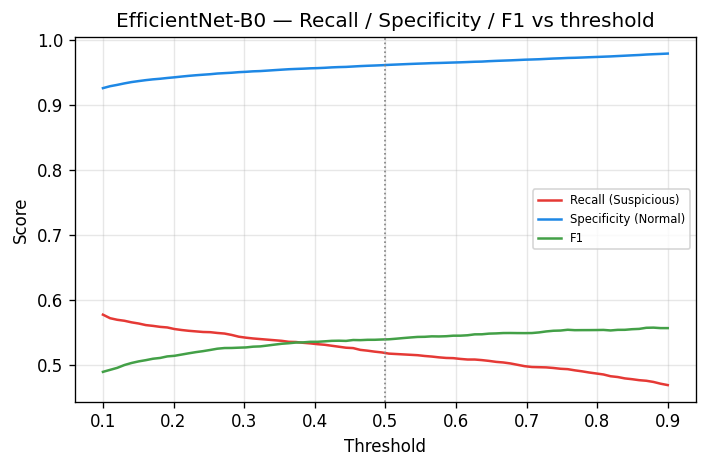

In [41]:
if label_tables:
    cfg = CONFIG_NAMES[0]
    all_logits, all_labels = [], []
    for fold, run_dir in all_runs[cfg].items():
        preds = load_preds(run_dir)
        if preds is None:
            continue
        logits, labels, _ = preds
        all_logits.append(logits)
        all_labels.append(labels)

    if all_logits:
        logits = np.concatenate(all_logits)
        labels = np.concatenate(all_labels)
        probs  = 1 / (1 + np.exp(-logits))

        thresholds = np.linspace(0.1, 0.9, 80)
        recalls, specificities, f1s = [], [], []
        for t in thresholds:
            p = (probs >= t).astype(int)
            tp = ((p == 1) & (labels == 1)).sum()
            fp = ((p == 1) & (labels == 0)).sum()
            tn = ((p == 0) & (labels == 0)).sum()
            fn = ((p == 0) & (labels == 1)).sum()
            rec  = tp / (tp + fn) if (tp + fn) > 0 else 0
            spec = tn / (tn + fp) if (tn + fp) > 0 else 0
            prec = tp / (tp + fp) if (tp + fp) > 0 else 0
            f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0
            recalls.append(rec)
            specificities.append(spec)
            f1s.append(f1)

        fig, ax = plt.subplots(figsize=(6, 4))
        ax.plot(thresholds, recalls,       label="Recall (Suspicious)", color="#e53935")
        ax.plot(thresholds, specificities, label="Specificity (Normal)", color="#1e88e5")
        ax.plot(thresholds, f1s,           label="F1",                  color="#43a047")
        ax.axvline(0.5, color="grey", ls=":", lw=1)
        ax.set_xlabel("Threshold")
        ax.set_ylabel("Score")
        ax.set_title(f"{DISPLAY_NAMES[cfg]} — Recall / Specificity / F1 vs threshold")
        ax.legend(fontsize=7)
        ax.grid(True, alpha=0.3)
        fig.tight_layout()
        plt.show()
else:
    print("No prediction data available yet.")

## 9 · Confusion matrix at optimal threshold

Re-estimates the confusion matrix using two threshold-selection strategies:
- **Youden's J** (recall + specificity − 1): maximises overall discriminative ability, preferred in clinical screening contexts.
- **Max F1**: maximises the harmonic mean of precision and recall.

C:\Users\jordi\AppData\Local\Temp\ipykernel_20172\3931580559.py:16: RuntimeWarning: overflow encountered in exp
  probs  = 1 / (1 + np.exp(-logits))


Threshold at max Youden's J : 0.060  (recall=0.594, spec=0.911)
Threshold at max F1         : 0.875  (F1=0.558)


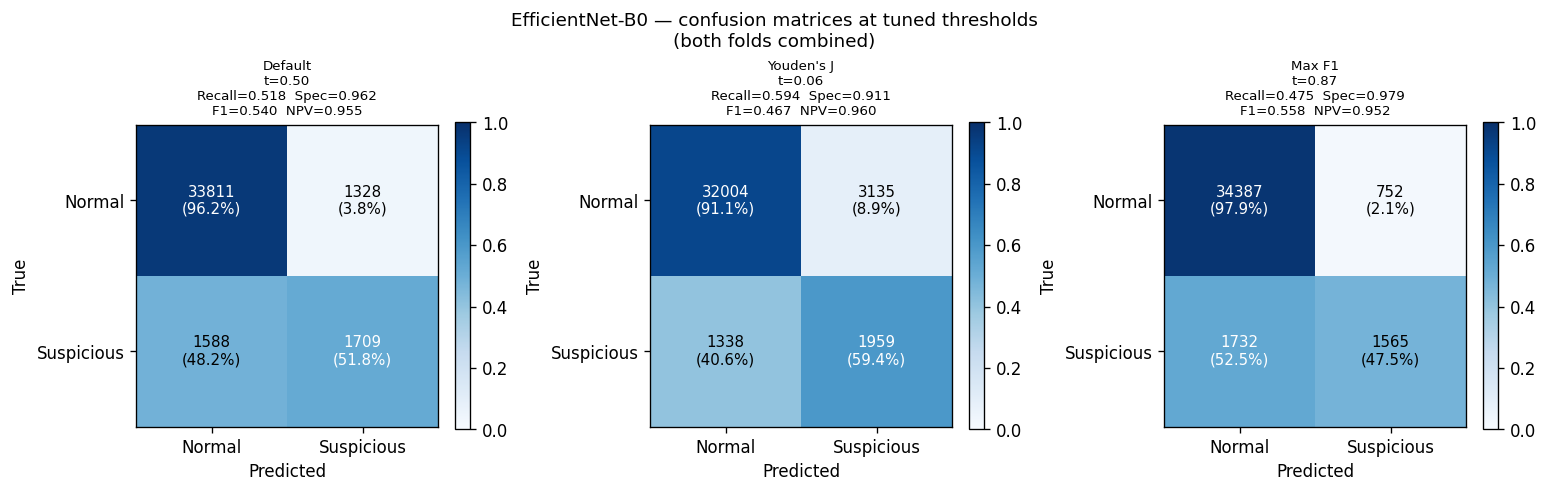

In [42]:
cfg = CONFIG_NAMES[0]
all_logits, all_labels = [], []
for fold, run_dir in all_runs[cfg].items():
    preds = load_preds(run_dir)
    if preds is None:
        continue
    logits, labels, _ = preds
    all_logits.append(logits)
    all_labels.append(labels)

if not all_logits:
    print("No prediction data available.")
else:
    logits = np.concatenate(all_logits)
    labels = np.concatenate(all_labels)
    probs  = 1 / (1 + np.exp(-logits))

    # Fine-grained threshold sweep
    thresholds_sweep = np.linspace(0.05, 0.95, 180)
    recalls_sw, specs_sw, f1s_sw = [], [], []
    for t in thresholds_sweep:
        p = (probs >= t).astype(int)
        tp = ((p == 1) & (labels == 1)).sum()
        fp = ((p == 1) & (labels == 0)).sum()
        tn = ((p == 0) & (labels == 0)).sum()
        fn = ((p == 0) & (labels == 1)).sum()
        rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
        prec_v = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        f1 = 2 * prec_v * rec / (prec_v + rec) if (prec_v + rec) > 0 else 0.0
        recalls_sw.append(rec); specs_sw.append(spec); f1s_sw.append(f1)

    recalls_sw = np.array(recalls_sw)
    specs_sw   = np.array(specs_sw)
    f1s_sw     = np.array(f1s_sw)
    youdens    = recalls_sw + specs_sw - 1

    opt_j   = float(thresholds_sweep[np.argmax(youdens)])
    opt_f1  = float(thresholds_sweep[np.argmax(f1s_sw)])

    print(f"Threshold at max Youden's J : {opt_j:.3f}  "
          f"(recall={recalls_sw[np.argmax(youdens)]:.3f}, spec={specs_sw[np.argmax(youdens)]:.3f})")
    print(f"Threshold at max F1         : {opt_f1:.3f}  "
          f"(F1={f1s_sw[np.argmax(f1s_sw)]:.3f})")

    # Confusion matrices side-by-side
    scenarios = [
        (0.5,    f"Default\nt=0.50"),
        (opt_j,  f"Youden's J\nt={opt_j:.2f}"),
        (opt_f1, f"Max F1\nt={opt_f1:.2f}"),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))

    for ax, (thr, subtitle) in zip(axes, scenarios):
        p = (probs >= thr).astype(int)
        cm = confusion_matrix(labels, p)
        cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True)

        im = ax.imshow(cm_pct, vmin=0, vmax=1, cmap="Blues")
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normal", "Suspicious"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normal", "Suspicious"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")

        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i,j]}\n({cm_pct[i,j]:.1%})",
                        ha="center", va="center",
                        color="white" if cm_pct[i, j] > 0.5 else "black", fontsize=9)

        tp_v = cm[1, 1]; fp_v = cm[0, 1]; tn_v = cm[0, 0]; fn_v = cm[1, 0]
        rec_v  = tp_v / (tp_v + fn_v) if (tp_v + fn_v) > 0 else 0.0
        spec_v = tn_v / (tn_v + fp_v) if (tn_v + fp_v) > 0 else 0.0
        prec_v = tp_v / (tp_v + fp_v) if (tp_v + fp_v) > 0 else 0.0
        f1_v   = 2 * prec_v * rec_v / (prec_v + rec_v) if (prec_v + rec_v) > 0 else 0.0
        npv_v  = tn_v / (tn_v + fn_v) if (tn_v + fn_v) > 0 else 0.0
        ax.set_title(
            f"{subtitle}\nRecall={rec_v:.3f}  Spec={spec_v:.3f}\nF1={f1_v:.3f}  NPV={npv_v:.3f}",
            fontsize=8,
        )
        plt.colorbar(im, ax=ax, fraction=0.046)

    fig.suptitle(f"{DISPLAY_NAMES[cfg]} — confusion matrices at tuned thresholds\n(both folds combined)", fontsize=11)
    fig.tight_layout()
    plt.show()

## 10 · Phase 7 diagnosis

In [43]:
sys.path.insert(0, str(Path("..") / "src"))
from kvasir_triage.eval.diagnose import classify_path, PR_AUC_THRESHOLD, NPV_THRESHOLD

if not summary_df.empty:
    print(f"Phase 7 thresholds: PR-AUC ≥ {PR_AUC_THRESHOLD}  &  NPV ≥ {NPV_THRESHOLD}\n")
    for cfg in CONFIG_NAMES:
        rows_cfg = summary_df[summary_df["model"] == DISPLAY_NAMES[cfg]]
        if rows_cfg.empty:
            continue
        mean_prauc = rows_cfg["pr_auc"].mean()
        mean_npv   = rows_cfg["npv"].mean()
        cv_metrics = {"aggregate": {
            "pr_auc": {"mean": mean_prauc},
            "npv":    {"mean": mean_npv},
        }}
        path = classify_path(cv_metrics)
        path_desc = {"A": "SUCCESS", "B": "Clever Hans", "C": "data-bound / underfit"}
        status = "✓" if path == "A" else "✗"
        print(f"  {status}  {DISPLAY_NAMES[cfg]:<30}  "
              f"PR-AUC={mean_prauc:.3f}  NPV={mean_npv:.3f}  →  Path {path} ({path_desc[path]})")
else:
    print("No completed runs to diagnose yet.")

Phase 7 thresholds: PR-AUC ≥ 0.85  &  NPV ≥ 0.95

  ✗  EfficientNet-B0                 PR-AUC=0.534  NPV=0.955  →  Path C (data-bound / underfit)
